#### To build a hybrid anomaly detection model using a sparse autoencoder, Isolation Forest, and XGBoost, follow these steps: First, load and clean your data to ensure it is accurate and relevant. Next, select key features and split the dataset into training and testing sets. Normalize the features through scaling to ensure they are equally weighted. Use a sparse autoencoder to reduce the dimensionality of the data, facilitating more efficient processing. Apply an Isolation Forest to initially identify and isolate potential anomalies. Further refine this detection with XGBoost, enhancing the model's accuracy, especially for subtle anomalies. Finally, evaluate the model using precision, recall, F1-score, and a confusion matrix to assess its overall performance and accuracy. This sequential approach leverages each method's strengths to create a robust and effective anomaly detection system.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.ensemble import IsolationForest
from xgboost import XGBClassifier
import tensorflow as tf
from tensorflow.keras import layers, models, regularizers
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras import regularizers
from sklearn.preprocessing import LabelEncoder

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model
from tensorflow.keras import regularizers

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    classification_report, confusion_matrix,
    ConfusionMatrixDisplay
)

from xgboost import XGBClassifier
from scipy.stats import wilcoxon


1557/1557 [==============================] - 2s 1ms/step
Precision: 0.980
Recall: 0.980
F1 Score: 0.979
              precision    recall  f1-score   support

           0       0.98      0.80      0.88       903
           1       0.98      1.00      0.99      9057

    accuracy                           0.98      9960
   macro avg       0.98      0.90      0.93      9960
weighted avg       0.98      0.98      0.98      9960



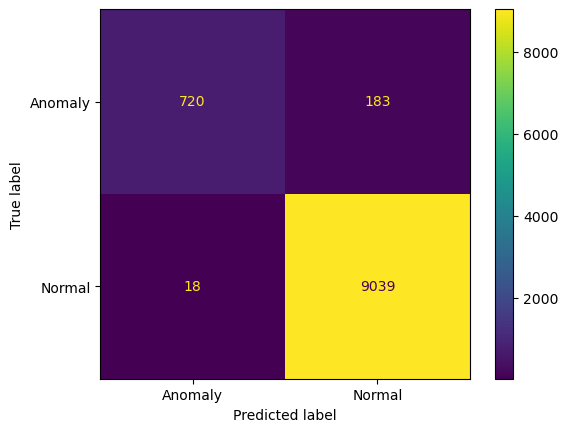

In [2]:

def hybrid_anomaly_detection_MAADM():
    # Load data from a CSV file
    data1 = pd.read_csv('pow_cons.csv')
    
    data = data1.sample(n=50000, random_state=5)
    
    data = data.drop(['Date','Time'], axis=1)
#     data.info()
    
    data.dropna(axis=0, inplace=True)
    
    #convert all the values in the columns into numeric
    for column in data.columns:
        data[column] = pd.to_numeric(data[column], errors='coerce')

    
    X = data.drop('Global_active_power', axis=1)  # Assuming 'Global_active_power' is the target column
    y_cont = data['Global_active_power']

    # First, binarize `y` based on a chosen threshold.
    y = np.where(y_cont > 0.2, 1, 0)  # Define `threshold` based on the dataset

    # Select top k features; k might be adjusted based on the dataset
    selector = SelectKBest(f_classif, k=3)
    X_selected = selector.fit_transform(X, y)
    
    
    # Dimensionality reduction with sparse autoencoder
    input_dim = X_selected.shape[1]
    encoding_dim = 32  # Dimension of the encoding layer
    input_layer = Input(shape=(input_dim,))
    encoded = Dense(encoding_dim, activation='relu', activity_regularizer=regularizers.l1(10e-5))(input_layer)
    decoded = Dense(input_dim, activation='sigmoid')(encoded)
    autoencoder = Model(inputs=input_layer, outputs=decoded)
    autoencoder.compile(optimizer='adam', loss='mean_squared_error')
    autoencoder.fit(X_selected, X_selected, epochs=50, batch_size=256, shuffle=True, verbose=0)
    
    encoder = Model(inputs=input_layer, outputs=encoded)
    X_encoded = encoder.predict(X_selected)
    
    # Split the data into train and test sets
    X_train, X_test, y_train, y_test = train_test_split(X_encoded, y, test_size=0.2, random_state=42)
    
    # Scale the features
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)
    
    # Use Isolation Forest to identify normal data points
    iso_forest = IsolationForest(contamination=0.1, n_estimators=100, random_state=42)
    iso_forest.fit(X_train_scaled)
    iso_preds = iso_forest.predict(X_train_scaled)
    
    # Filter only normal data points as identified by Isolation Forest
    normal_indices = np.where(iso_preds == 1)[0]  # Assuming '1' is normal
    X_train_normal = X_train_scaled[normal_indices]
    y_train_normal = y_train[normal_indices]
    
    # Train XGBoost on the filtered normal data
    xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss', random_state=42)
    xgb.fit(X_train_normal, y_train_normal)
    
    # Predict using XGBoost on the test set
    xgb_preds = xgb.predict(X_test_scaled)
    
    # Evaluate the final outcome from XGBoost
    precision = precision_score(y_test, xgb_preds, average='weighted', zero_division=0)
    recall = recall_score(y_test, xgb_preds, average='weighted', zero_division=0)
    f1 = f1_score(y_test, xgb_preds, average='weighted', zero_division=0)
    
    print(f'Precision: {precision:.3f}')
    print(f'Recall: {recall:.3f}')
    print(f'F1 Score: {f1:.3f}')
    
    print(classification_report(y_test, xgb_preds))


    # Display the confusion matrix
    cm = confusion_matrix(y_test, xgb_preds, labels=[0, 1])
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Anomaly', 'Normal'])
    disp.plot()
    plt.show()
    

hybrid_anomaly_detection_MAADM()




Running Power Consumption MAADM - Seed 5
Precision: 0.9790 | Recall: 0.9789 | F1: 0.9779
              precision    recall  f1-score   support

     Class 0       0.98      0.79      0.87       926
     Class 1       0.98      1.00      0.99      9034

    accuracy                           0.98      9960
   macro avg       0.98      0.89      0.93      9960
weighted avg       0.98      0.98      0.98      9960



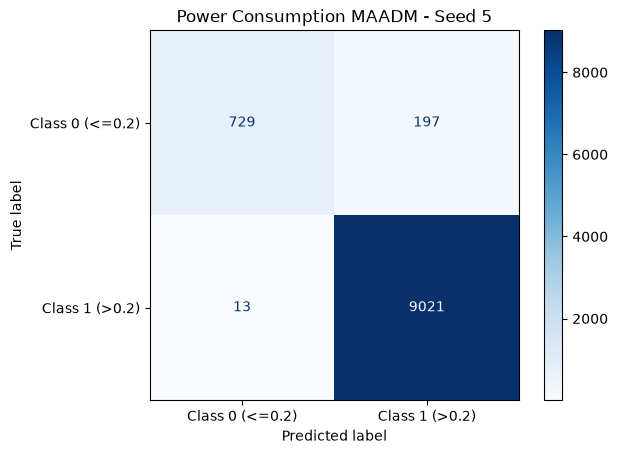


Running Power Consumption MAADM - Seed 21
Precision: 0.9792 | Recall: 0.9791 | F1: 0.9781
              precision    recall  f1-score   support

     Class 0       0.98      0.79      0.88       926
     Class 1       0.98      1.00      0.99      9034

    accuracy                           0.98      9960
   macro avg       0.98      0.89      0.93      9960
weighted avg       0.98      0.98      0.98      9960



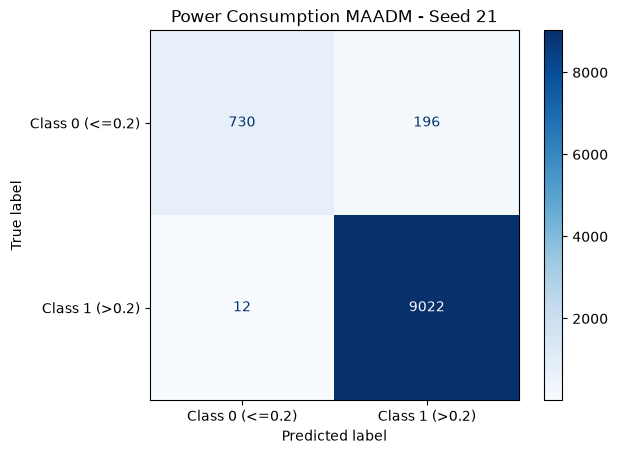


Running Power Consumption MAADM - Seed 42
Precision: 0.9771 | Recall: 0.9773 | F1: 0.9762
              precision    recall  f1-score   support

     Class 0       0.97      0.78      0.87       926
     Class 1       0.98      1.00      0.99      9034

    accuracy                           0.98      9960
   macro avg       0.97      0.89      0.93      9960
weighted avg       0.98      0.98      0.98      9960



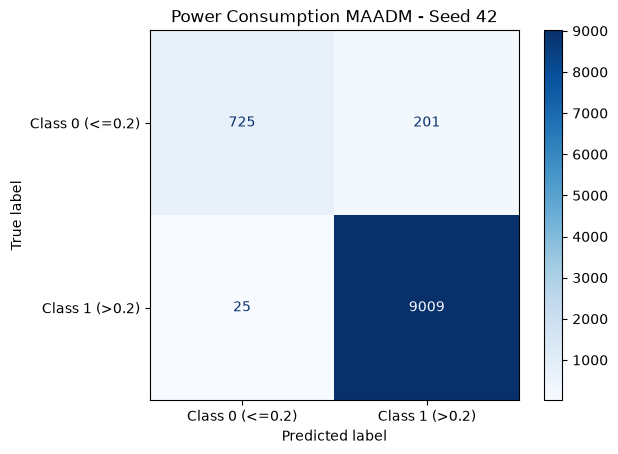


Running Power Consumption MAADM - Seed 77
Precision: 0.9804 | Recall: 0.9803 | F1: 0.9794
              precision    recall  f1-score   support

     Class 0       0.98      0.80      0.88       926
     Class 1       0.98      1.00      0.99      9034

    accuracy                           0.98      9960
   macro avg       0.98      0.90      0.94      9960
weighted avg       0.98      0.98      0.98      9960



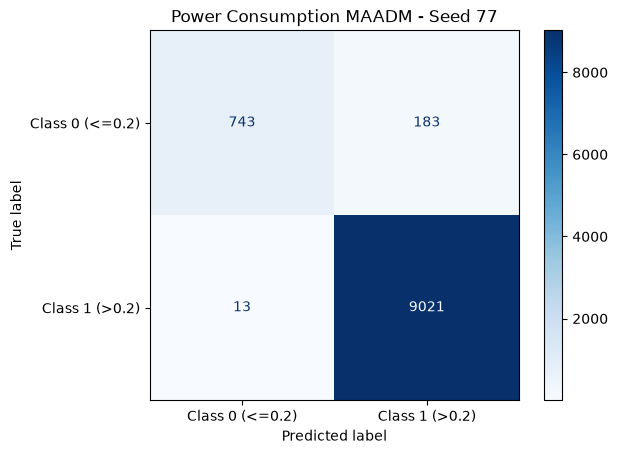


Running Power Consumption MAADM - Seed 100
Precision: 0.9789 | Recall: 0.9789 | F1: 0.9779
              precision    recall  f1-score   support

     Class 0       0.98      0.79      0.87       926
     Class 1       0.98      1.00      0.99      9034

    accuracy                           0.98      9960
   macro avg       0.98      0.89      0.93      9960
weighted avg       0.98      0.98      0.98      9960



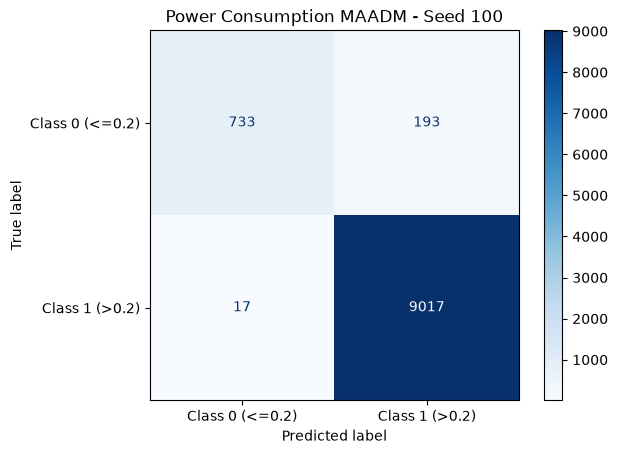


Individual Seed Results
 Seed  Precision   Recall       F1  Class1_Precision  Class1_Recall  Class1_F1
    5   0.978987 0.978916 0.977859          0.978629       0.998561   0.988494
   21   0.979211 0.979116 0.978070          0.978737       0.998672   0.988604
   42   0.977106 0.977309 0.976227          0.978176       0.997233   0.987612
   77   0.980367 0.980321 0.979419          0.980117       0.998561   0.989253
  100   0.978885 0.978916 0.977910          0.979045       0.998118   0.988489

MAADM: Mean ± Standard Deviation
          Metric     Mean      Std       Mean ± SD
       Precision 0.978911 0.001170 0.9789 ± 0.0012
          Recall 0.978916 0.001072 0.9789 ± 0.0011
              F1 0.977897 0.001133 0.9779 ± 0.0011
Class1_Precision 0.978941 0.000728 0.9789 ± 0.0007
   Class1_Recall 0.998229 0.000596 0.9982 ± 0.0006
       Class1_F1 0.988491 0.000584 0.9885 ± 0.0006


In [2]:
def hybrid_anomaly_detection_MAADM():

    # Five experimental random seeds
    seeds = [5, 21, 42, 77, 100]
    results = []

    # Load Household Power Consumption dataset
    data1 = pd.read_csv("pow_cons.csv")

    # Fixed sampling configuration
    data = data1.sample(
        n=50000,
        random_state=5
    ).copy()

    # Remove Date and Time columns
    data = data.drop(
        columns=["Date", "Time"],
        errors="ignore"
    )

    # Convert all columns to numeric
    for column in data.columns:
        data[column] = pd.to_numeric(
            data[column],
            errors="coerce"
        )

    # Remove missing values after conversion
    data = data.dropna(axis=0).copy()

    # Target and predictor variables
    X = data.drop(columns=["Global_active_power"])
    y_cont = data["Global_active_power"]

    # Binary classification threshold
    y = pd.Series(
        np.where(y_cont > 0.2, 1, 0),
        index=data.index
    )

    for seed in seeds:

        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(seed)

        print(f"\nRunning Power Consumption MAADM - Seed {seed}")

        # Split before feature selection and autoencoder
        X_train, X_test, y_train, y_test = train_test_split(
            X, y,
            test_size=0.2,
            random_state=seed,
            stratify=y
        )

        # Select top 3 features
        selector = SelectKBest(
            score_func=f_classif,
            k=3
        )

        X_train_selected = selector.fit_transform(
            X_train, y_train
        )

        X_test_selected = selector.transform(
            X_test
        )

        # Scale selected input features
        input_scaler = StandardScaler()

        X_train_selected = input_scaler.fit_transform(
            X_train_selected
        )

        X_test_selected = input_scaler.transform(
            X_test_selected
        )

        # Sparse Autoencoder
        input_dim = X_train_selected.shape[1]
        encoding_dim = 32

        input_layer = Input(shape=(input_dim,))

        encoded = Dense(
            encoding_dim,
            activation="relu",
            activity_regularizer=regularizers.l1(10e-5)
        )(input_layer)

        decoded = Dense(
            input_dim,
            activation="linear"
        )(encoded)

        autoencoder = Model(
            inputs=input_layer,
            outputs=decoded
        )

        autoencoder.compile(
            optimizer="adam",
            loss="mean_squared_error"
        )

        autoencoder.fit(
            X_train_selected,
            X_train_selected,
            epochs=50,
            batch_size=256,
            shuffle=True,
            verbose=0
        )

        # Extract encoded features
        encoder = Model(
            inputs=input_layer,
            outputs=encoded
        )

        X_train_encoded = encoder.predict(
            X_train_selected,
            verbose=0
        )

        X_test_encoded = encoder.predict(
            X_test_selected,
            verbose=0
        )

        # Scale encoded features
        scaler = StandardScaler()

        X_train_scaled = scaler.fit_transform(
            X_train_encoded
        )

        X_test_scaled = scaler.transform(
            X_test_encoded
        )

        # Isolation Forest
        iso_forest = IsolationForest(
            contamination=0.1,
            n_estimators=100,
            random_state=seed
        )

        iso_forest.fit(X_train_scaled)

        iso_preds = iso_forest.predict(
            X_train_scaled
        )

        # Retain inliers identified by Isolation Forest
        normal_indices = np.where(
            iso_preds == 1
        )[0]

        X_train_normal = X_train_scaled[
            normal_indices
        ]

        y_train_normal = y_train.iloc[
            normal_indices
        ]

        if y_train_normal.nunique() < 2:
            raise ValueError(
                f"Seed {seed}: only one class "
                "remains after Isolation Forest."
            )

        # XGBoost classification
        xgb = XGBClassifier(
            n_estimators=100,
            max_depth=6,
            learning_rate=0.3,
            eval_metric="logloss",
            random_state=seed,
            n_jobs=1
        )

        xgb.fit(
            X_train_normal,
            y_train_normal
        )

        # Predict test observations
        xgb_preds = xgb.predict(
            X_test_scaled
        )

        # Weighted evaluation metrics
        precision = precision_score(
            y_test, xgb_preds,
            average="weighted",
            zero_division=0
        )

        recall = recall_score(
            y_test, xgb_preds,
            average="weighted",
            zero_division=0
        )

        f1 = f1_score(
            y_test, xgb_preds,
            average="weighted",
            zero_division=0
        )

        # Class 1 metrics
        class1_precision = precision_score(
            y_test, xgb_preds,
            pos_label=1,
            zero_division=0
        )

        class1_recall = recall_score(
            y_test, xgb_preds,
            pos_label=1,
            zero_division=0
        )

        class1_f1 = f1_score(
            y_test, xgb_preds,
            pos_label=1,
            zero_division=0
        )

        # Store results
        results.append({
            "Seed": seed,
            "Precision": precision,
            "Recall": recall,
            "F1": f1,
            "Class1_Precision": class1_precision,
            "Class1_Recall": class1_recall,
            "Class1_F1": class1_f1
        })

        print(
            f"Precision: {precision:.4f} | "
            f"Recall: {recall:.4f} | "
            f"F1: {f1:.4f}"
        )

        print(
            classification_report(
                y_test,
                xgb_preds,
                target_names=["Class 0", "Class 1"],
                zero_division=0
            )
        )

        # Confusion matrix
        cm = confusion_matrix(
            y_test,
            xgb_preds,
            labels=[0, 1]
        )

        disp = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=[
                "Class 0 (<=0.2)",
                "Class 1 (>0.2)"
            ]
        )

        disp.plot(cmap="Blues")

        plt.title(
            f"Power Consumption MAADM - Seed {seed}"
        )

        plt.show()

    # Results for individual seeds
    results_df = pd.DataFrame(results)

    print("\nIndividual Seed Results")
    print(results_df.to_string(index=False))

    # Mean ± standard deviation
    summary_rows = []

    for metric in [
        "Precision",
        "Recall",
        "F1",
        "Class1_Precision",
        "Class1_Recall",
        "Class1_F1"
    ]:

        mean = results_df[metric].mean()
        std = results_df[metric].std(ddof=1)

        summary_rows.append({
            "Metric": metric,
            "Mean": mean,
            "Std": std,
            "Mean ± SD": f"{mean:.4f} ± {std:.4f}"
        })

    summary_df = pd.DataFrame(summary_rows)

    print("\nMAADM: Mean ± Standard Deviation")
    print(summary_df.to_string(index=False))

    # Save results
    results_df.to_csv(
        "POW_MAADM_seed_results.csv",
        index=False
    )

    summary_df.to_csv(
        "POW_MAADM_summary.csv",
        index=False
    )

    return results_df, summary_df


# Execute MAADM
pow_results, pow_summary = (
    hybrid_anomaly_detection_MAADM()
)
